In [7]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
print("✅ Library berhasil di-import!")

✅ Library berhasil di-import!


In [8]:
# Membaca dataset
df = pd.read_csv('Well_Dataset.csv')
print(f"Dimensi Data: {df.shape[0]:,} baris × {df.shape[1]} kolom")

Dimensi Data: 2,060 baris × 14 kolom


In [9]:
# Melihat 5 baris pertama
df.head()

,Formation,TMD (m),TVD (m),ROP (m/hr),WOB (ton),FR (gpm),SPP (psi),RPM (rpm),TQ (lb.ft),MW IN (ppg),MW OUT (ppg),RETURN (%),BIT TIME (hr),DATE TIME
0,Seno,428,428.01,33.3,3,514.3,818,70.0,1915.0,10.4,10.401,44,0.01,19/06/2010 07.12.15
1,Seno,428,428.01,33.3,3,514.3,818,70.0,1915.0,10.4,10.401,44,0.01,19/06/2010 07.12.15
2,Seno,429,429.01,39.3,4,428.8,554,79.0,2383.0,10.4,10.403,40,0.05,19/06/2010 07.14.23
3,Seno,429,429.01,39.3,4,428.8,554,79.0,2383.0,10.4,10.403,40,0.05,19/06/2010 07.14.23
4,Seno,430,430.00,26.7,3,442.7,547,79.0,2499.0,10.4,10.405,40,0.09,19/06/2010 07.16.43


In [10]:
# Melihat formasi unik
print("🏷️ Formasi yang Ditembus:")
for f in df['Formation'].unique():
    print(f"  • {f}: {len(df[df['Formation']==f]):,} pts")

🏷️ Formasi yang Ditembus:
  • Seno: 342 pts
  • Turo: 89 pts
  • Ceno: 203 pts
  • Albi: 213 pts
  • Apti: 36 pts
  • Barre: 411 pts
  • Neo: 265 pts
  • Malcolm: 205 pts
  • Eren Shale: 252 pts
  • Mikasa Anhydrite: 44 pts


In [11]:
# Identifikasi missing values
missing = df.isnull().sum()
print("❓ Missing Values:")
for col in df.columns:
    if missing[col] > 0:
        print(f"  ⚠️ {col}: {missing[col]}")

❓ Missing Values:
  ⚠️ RPM (rpm): 1
  ⚠️ TQ (lb.ft): 1


In [12]:
#Interpolasi linear untuk mengisi missing values
df['RPM (rpm)'] = df['RPM (rpm)'].interpolate(method='linear')
df['TQ (lb.ft)'] = df['TQ (lb.ft)'].interpolate(method='linear')

print("✅ Missing values setelah interpolasi: 0")

✅ Missing values setelah interpolasi: 0


In [13]:
# Menghitung dan menghapus duplikat
duplicates = df.duplicated().sum()
print(f"🔍 Jumlah baris duplikat: {duplicates}")

df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"📊 Jumlah baris setelah cleaning: {len(df):,}")

🔍 Jumlah baris duplikat: 2
📊 Jumlah baris setelah cleaning: 2,058


In [14]:
# Konversi datetime
df['DATE TIME'] = pd.to_datetime(df['DATE TIME'], format='%d/%m/%Y %H.%M.%S')

print("📅 Rentang Waktu:")
print(f"   Mulai  : {df['DATE TIME'].min()}")
print(f"   Selesai: {df['DATE TIME'].max()}")

📅 Rentang Waktu:
   Mulai  : 2010-06-19 07:12:15
   Selesai: 2010-06-23 01:37:16


In [15]:
# Feature Engineering
df['MW_DIFF'] = df['MW OUT (ppg)'] - df['MW IN (ppg)']

df['DEPTH_CAT'] = pd.cut(df['TVD (m)'],
    bins=[0, 1000, 1500, 2000, 3000],
    labels=['Shallow', 'Medium', 'Deep', 'Very Deep'])

df['FORMATION_CODE'] = df['Formation'].astype('category').cat.codes

print("✅ Feature baru: MW_DIFF, DEPTH_CAT, FORMATION_CODE")

✅ Feature baru: MW_DIFF, DEPTH_CAT, FORMATION_CODE


In [16]:
# Statistik deskriptif
df[['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)', 'TQ (lb.ft)']].describe().round(2)

,ROP (m/hr),WOB (ton),RPM (rpm),TQ (lb.ft)
count,2058.00,2058.00,2058.00,2058.00
mean,72.52,8.74,156.35,9213.45
std,32.64,3.59,23.84,3168.78
min,3.10,0.00,70.00,784.00
25%,49.72,7.00,146.00,6946.50
50%,67.20,9.00,158.00,9147.50
75%,91.88,11.00,167.00,11404.50
max,203.20,22.00,199.00,19822.00


In [17]:
# Rata-rata ROP per formasi
rop_by_formation = df.groupby('Formation')['ROP (m/hr)'].mean().sort_values(ascending=False)
print(rop_by_formation.round(2))

Formation
Albi                107.95
Neo                  88.50
Ceno                 87.61
Barre                77.36
Turo                 71.85
Seno                 62.29
Malcolm              52.14
Eren Shale           48.73
Apti                 47.53
Mikasa Anhydrite     22.12
Name: ROP (m/hr), dtype: float64


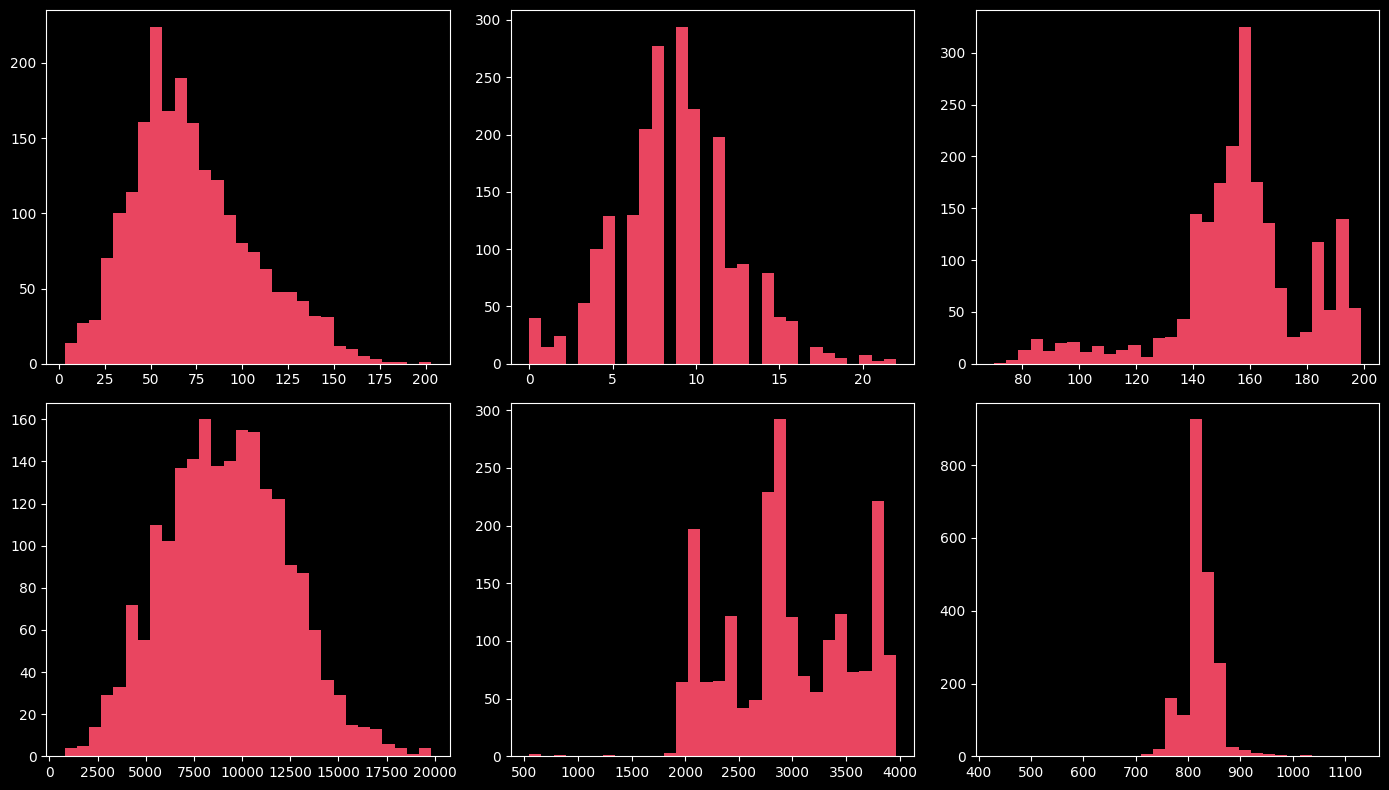

In [18]:
# Histogram distribusi parameter drilling
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
params = ['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)', 'TQ (lb.ft)', 'SPP (psi)', 'FR (gpm)']
for ax, param in zip(axes.flatten(), params):
    ax.hist(df[param], bins=30, color='#e94560')
plt.tight_layout(); plt.show()

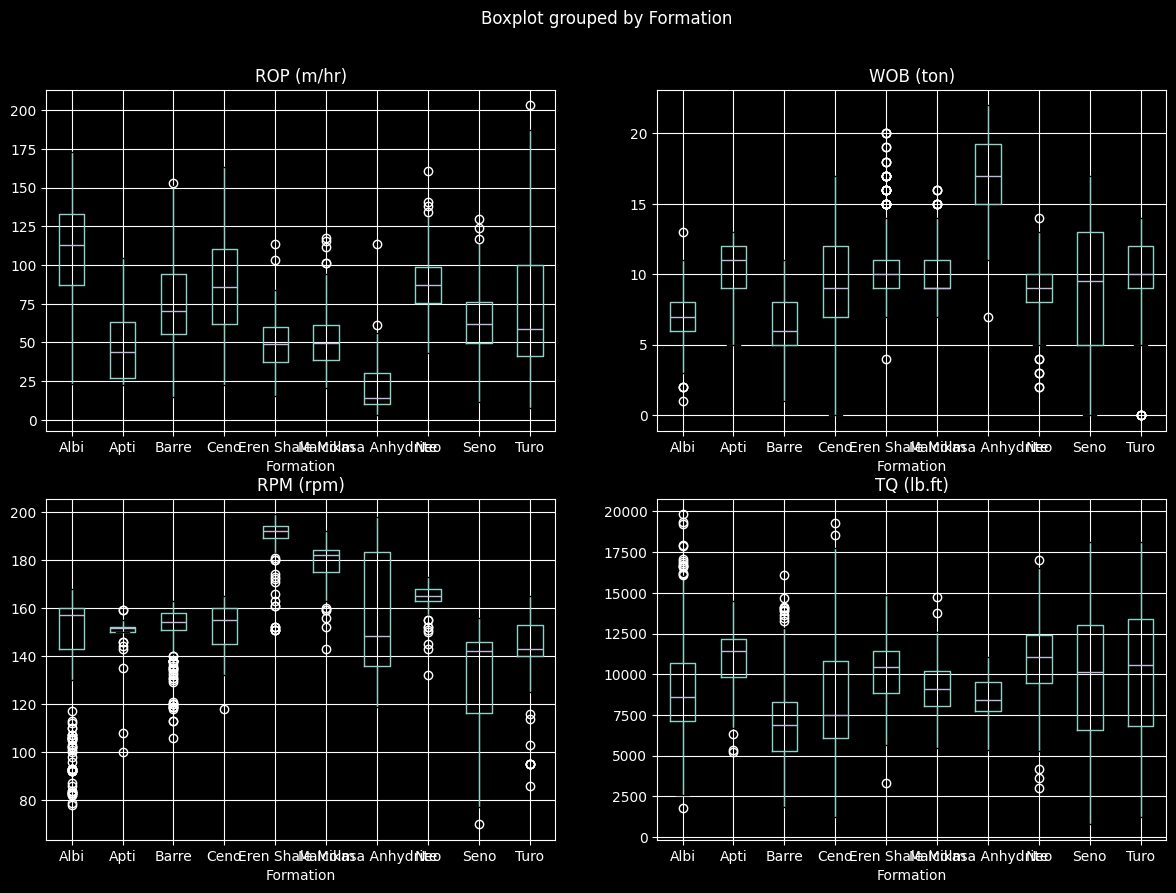

In [27]:
# Boxplot per formasi
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, param in zip(axes.flatten(), ['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)', 'TQ (lb.ft)']):
    df.boxplot(column=param, by='Formation', ax=ax)
plt.show()

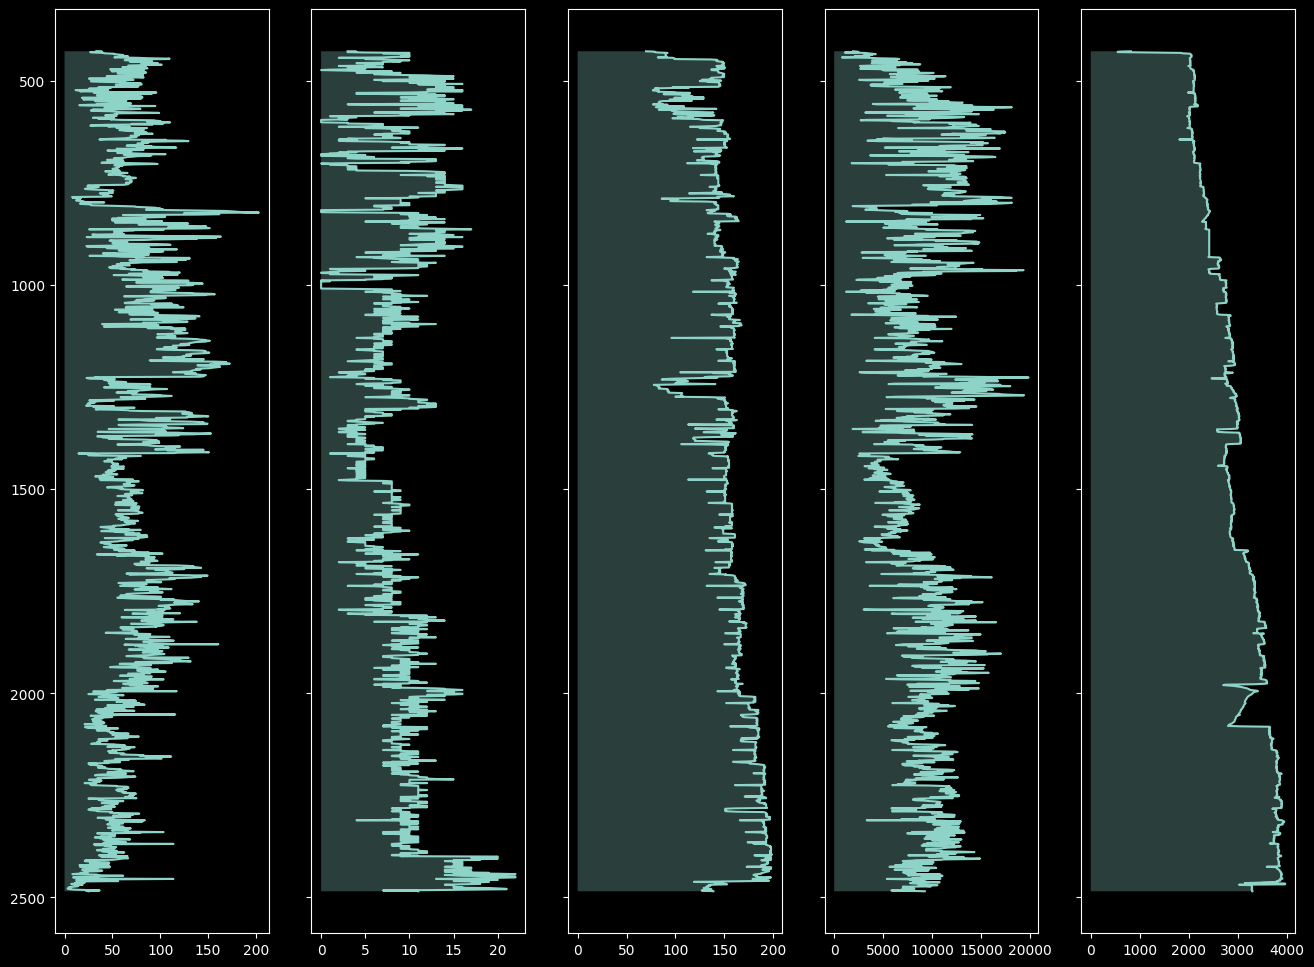

In [20]:
# Well Log Style Plot - Parameter vs Kedalaman
fig, axes = plt.subplots(1, 5, figsize=(16, 12), sharey=True)
params = ['ROP (m/hr)', 'WOB (ton)', 'RPM (rpm)', 'TQ (lb.ft)', 'SPP (psi)']
for ax, param in zip(axes, params):
    ax.plot(df[param], df['TVD (m)'])
    ax.fill_betweenx(df['TVD (m)'], 0, df[param], alpha=0.3)
axes[0].invert_yaxis()
plt.show()

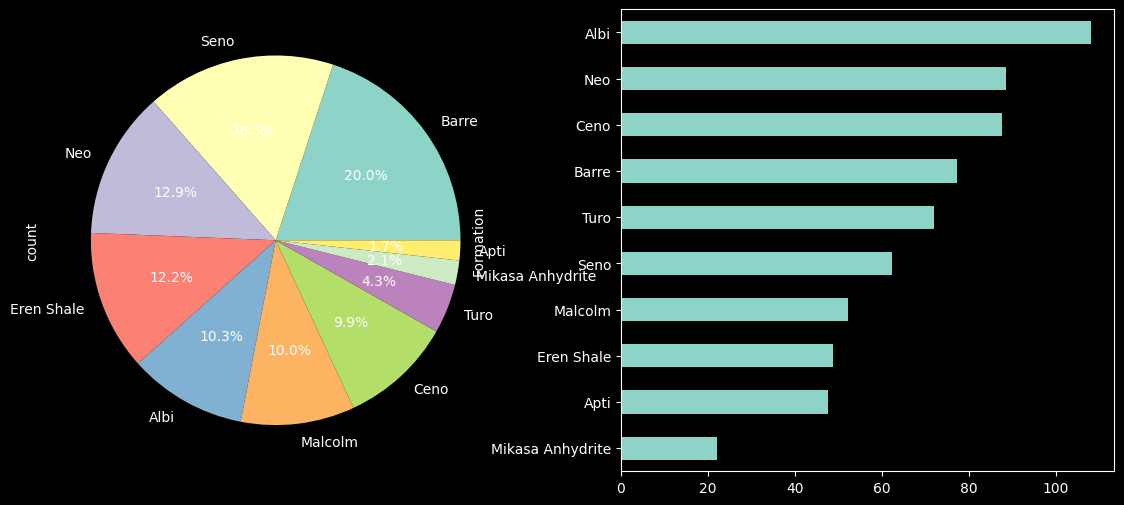

In [21]:
# Distribusi dan rata-rata ROP per formasi
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
df['Formation'].value_counts().plot.pie(ax=axes[0], autopct='%1.1f%%')
df.groupby('Formation')['ROP (m/hr)'].mean().sort_values().plot.barh(ax=axes[1])
plt.show()

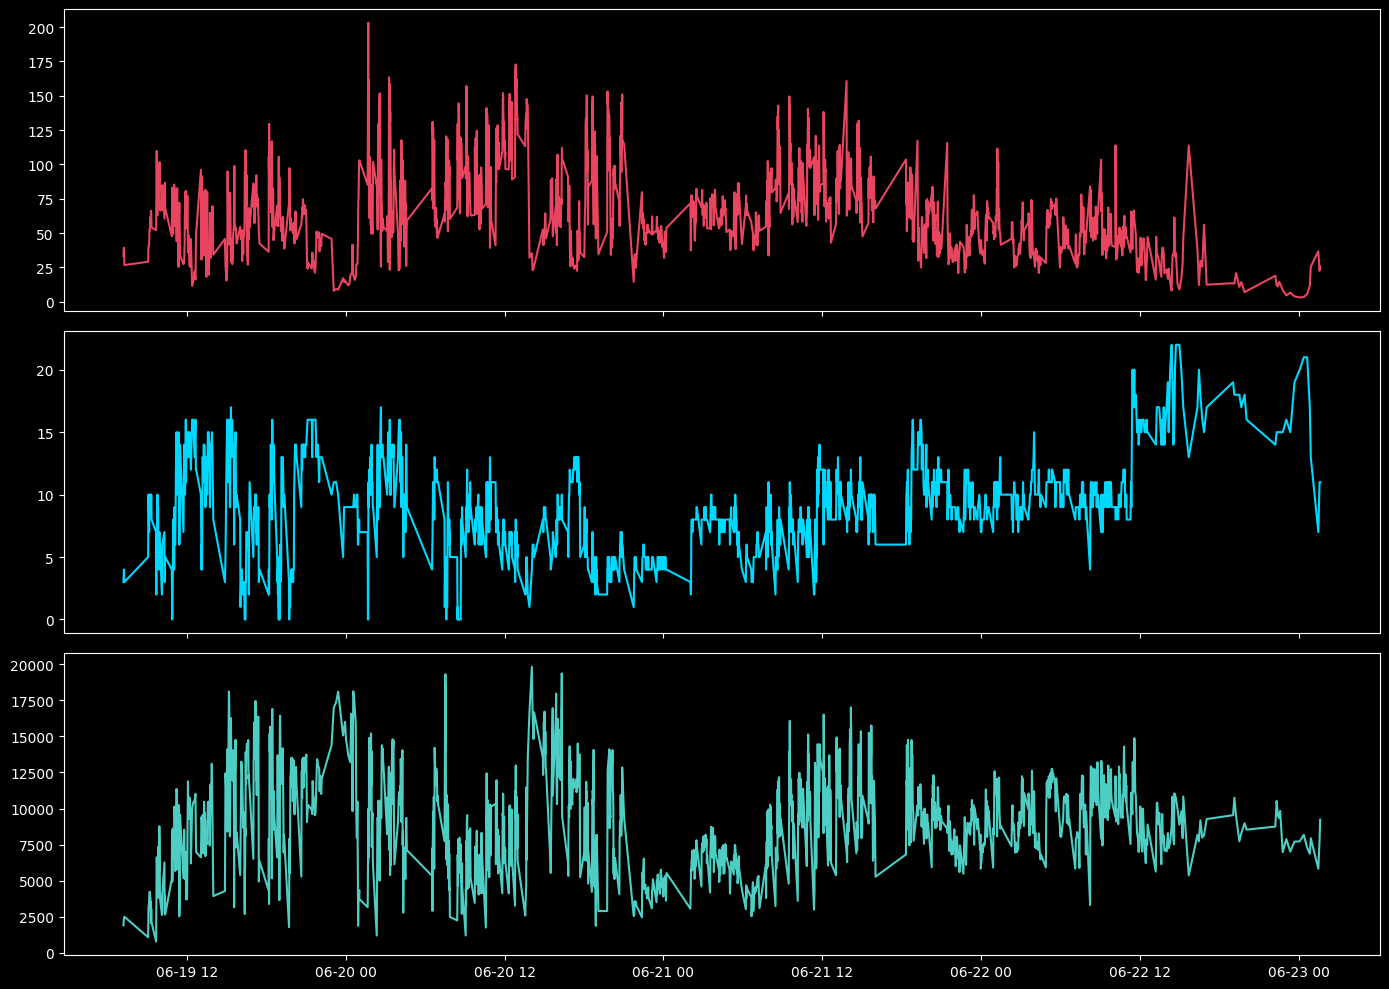

In [22]:
# Time series plot
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
axes[0].plot(df['DATE TIME'], df['ROP (m/hr)'], color='#e94560')
axes[1].plot(df['DATE TIME'], df['WOB (ton)'], color='#00d9ff')
axes[2].plot(df['DATE TIME'], df['TQ (lb.ft)'], color='#4ecdc4')
plt.tight_layout(); plt.show()

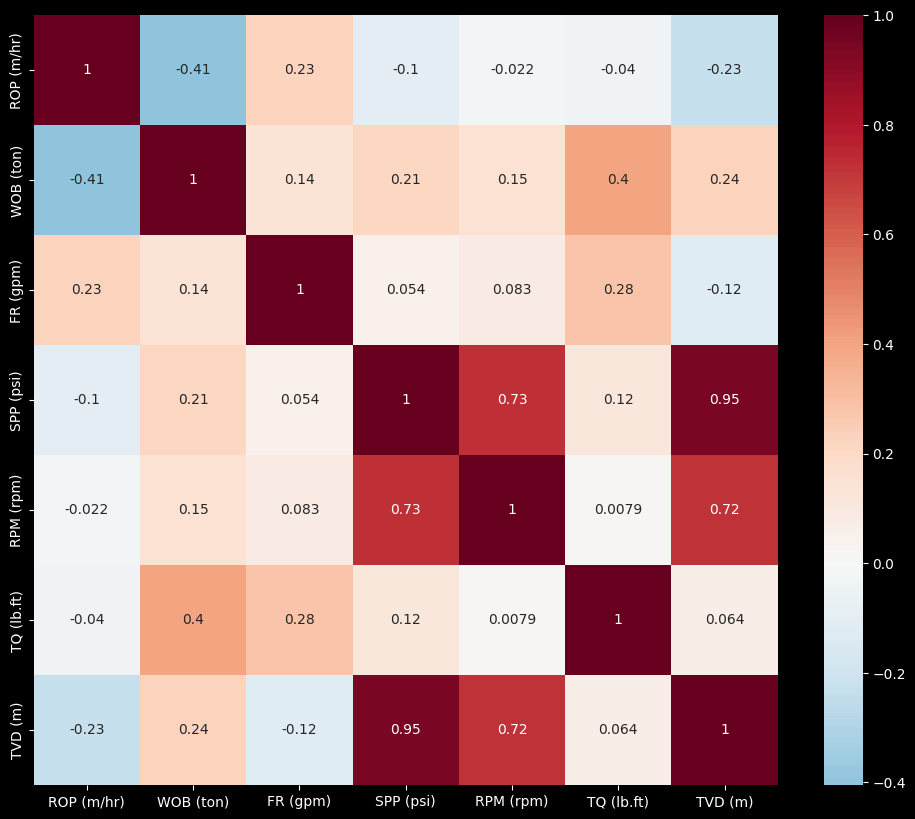

In [23]:
# Correlation heatmap
cols = ['ROP (m/hr)', 'WOB (ton)', 'FR (gpm)', 'SPP (psi)', 'RPM (rpm)', 'TQ (lb.ft)', 'TVD (m)']
corr = df[cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0)
plt.show()

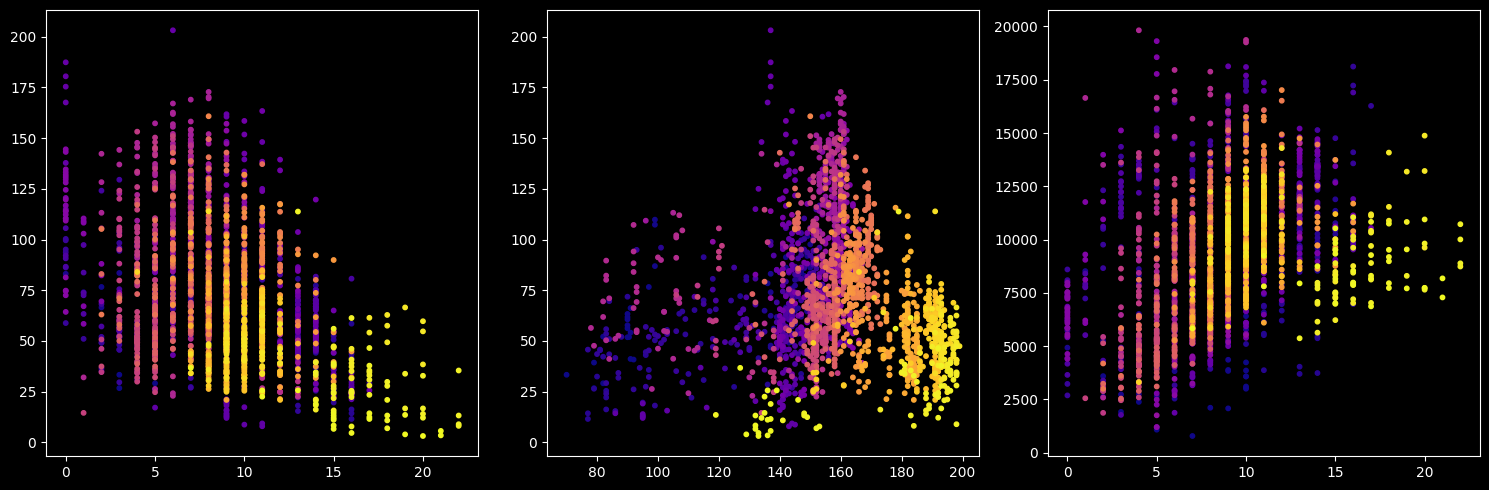

In [24]:
# Scatter plots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].scatter(df['WOB (ton)'], df['ROP (m/hr)'], c=df['TVD (m)'], cmap='plasma', s=10)
axes[1].scatter(df['RPM (rpm)'], df['ROP (m/hr)'], c=df['TVD (m)'], cmap='plasma', s=10)
axes[2].scatter(df['WOB (ton)'], df['TQ (lb.ft)'], c=df['TVD (m)'], cmap='plasma', s=10)
plt.tight_layout(); plt.show()